# A4 - Random numbers and distributions
Probability and Statistics<br>
Name(s): Vilho Pesonen<br>
Date: 25.11.2026 <br>
[Helsinki Metropolia University of Applied Sciences](https://www.metropolia.fi/en)


In [57]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy.random as rng

# Problem 1. Birth weight

In this first problem we study babies' birth weight data, which has used for [a machine learning competition at Kaggle](https://www.kaggle.com/competitions/birth-weight-prediction/data). Your aim is to analyse the data and compare it against the normal distribution.

## 1.1. Descriptive analysis of the dataset

- Read in the dataset using pandas read_csv function. Remember to store the dataset into same folder where this Notebook is.
- Select the `BWEIGHT` for more detailed analysis.
- Create a histogram of the birth weight data.
- Calculate also the descriptive statistics.

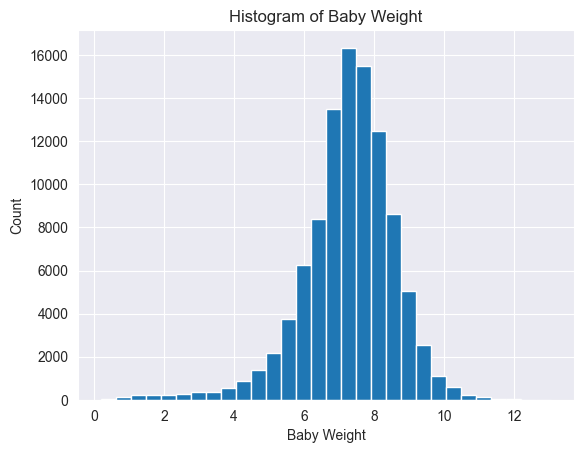

count    101400.000000
mean          7.258066
std           1.329461
min           0.187500
25%           6.625000
50%           7.375000
75%           8.062500
max          13.062500
Name: BWEIGHT, dtype: float64

In [63]:
# Your code
data = pd.read_csv('baby-weights-dataset.csv')
bweight = data['BWEIGHT']
plt.hist(bweight, bins=30)
plt.xlabel("Baby Weight")
plt.ylabel("Count")
plt.title("Histogram of Baby Weight")
plt.show()
bweight.describe()

**Questions**

- a) How many babies there were in this dataset?
- b) What was the average ($\mu$) of the birth weight?
- c) What was the standard deviation ($\sigma$) of the birth weight?
- d) What were the minimum and maximum values for the birth weight?
- e) What do you think are the units for the birth weight? Explain.

**Answers**

- a) 101400
- b) 7.258
- c) 1.329
- d) Min: 0.187, Max: 13.062
- e) Pounds because 7.25 lbs is 3.29kg which is average weight for baby. If the datasheet was in kgs then the max weight for baby would be 13kg which is not normal

## 1.2. Calculations

Using the birth weight data, calculate:
- f) What is the probability that the birth weight is less than 4?
- g) What is the probability that the birth weight is more than 10?
- h) What is the probability that the birth weight is between $\mu - 2\sigma$ and $\mu + 2\sigma$?

In [59]:
# Your code
less=(bweight<4).mean()
print(f"Probability of less than 4 is {less:.2%}")
more=(bweight>10).mean()
print(f"Probability of more than 10 is {more:.2%}")
mu=bweight.mean()
sigma=bweight.std()
x1=mu-2*sigma
x2=mu+2*sigma
between=((bweight>=x1) & (bweight<=x2)).mean()
print(f"Probability that the weight is between {x1:.2} and {x2:.2} is {between:.2%}")

Probability of less than 4 is 2.26%
Probability of more than 10 is 0.98%
Probability that the weight is between 4.6 and 9.9 is 95.18%


**Answers**

- f) 2.26%
- g) 0.98%
- h) 95.18%

## 1.3. Generate random numbers based on statistics

Based on the descriptive statistics generate random numbers from normal distribution. Use the same mean, standard deviation, and size (=count) as calculated from the data.

Calculate the descriptive statistics for the generated data. Make also a histogram.

- i) Compare the generated random number results to the original. What do you observe? Similarities? Differences?
- k) How would you describe the distribution of the birth weight?


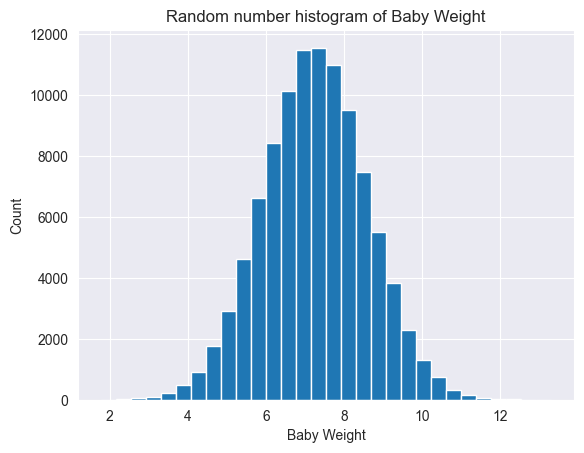

count    101400.000000
mean          7.251915
std           1.331964
min           1.760577
25%           6.350293
50%           7.250365
75%           8.147316
max          13.310370
dtype: float64

In [60]:
# Your code
mean=bweight.mean()
standard=bweight.std()
size=bweight.count()
x=rng.normal(mean,standard,size)
plt.hist(x,bins=30)
plt.xlabel("Baby Weight")
plt.ylabel("Count")
plt.title("Random number histogram of Baby Weight")
plt.show()
pd.Series(x).describe()

**Answer:**

- i) Similarities: mean and std are almost the same. Maximum values are almost the same. Differences: Minum values are very different.
- k) The distribution is a bell curve. The normal distribution had more variaty in data, it is less bell curve.

---
# Problem 2. Arrival times

The aim of this problem is to learn to use [exponential distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html). We use the values given in YouTube video **[Example distribution](https://www.youtube.com/watch?v=4PEX-SuftjQ)**.

**Coding**
- Create an array of 2 000 [exponentially distributed](https://en.wikipedia.org/wiki/Exponential_distribution) random numbers having the parameter value $\lambda$ given in the Youtube video.
- Draw a histogram of the values. (Remember to tune the bin settings properly).
- Draw also a boxplot of the values.
- Calculate the descriptive statistics for the data.
- Calculate the probability that the data value is between 2 and 4.


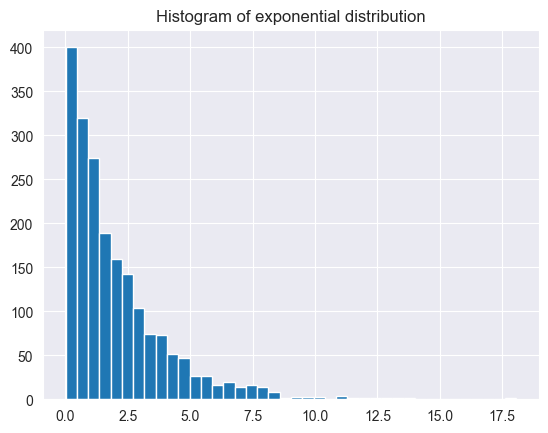

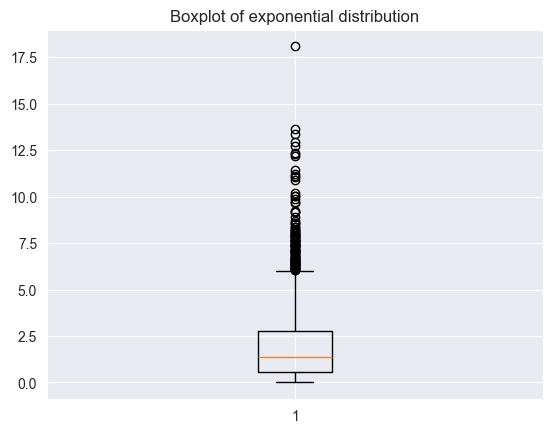

count    2000.000000
mean        2.022733
std         2.038235
min         0.001100
25%         0.587420
50%         1.366087
75%         2.752717
max        18.068778
dtype: float64
Probability that the values is between 2-4 is 23.95%
interquartile range is 2.1652967755007997
Probability that the value is between 2-4 is 0.2395


In [61]:
# Your code
lam=0.5
scale=1/lam
x=rng.exponential(scale,2000)
plt.hist(x,bins=40)
plt.title("Histogram of exponential distribution")
plt.show()
plt.boxplot(x)
plt.title("Boxplot of exponential distribution")
plt.show()
print(pd.Series(x).describe())
p=((x>=2)&(x<=4)).mean()
print(f"Probability that the values is between 2-4 is {p:.2%}")
irq=np.percentile(x,75)- np.percentile(x,25)
print(f"interquartile range is {irq}")
between=((x>2)&(x<4)).mean()
print(f"Probability that the value is between 2-4 is {between}")

**Questions:**
- a) What is the value for $\lambda$?
- b) What does the variable x present (in video)?
- c) What is the median value calculated from the array? How much does it differ from the analytical (calculated with paper and pen) value given in video?
- d) What is the [interquartile range](https://en.wikipedia.org/wiki/Interquartile_range) for this data?
- e) How much do the analytical probability $P(2 < x < 4)$ (see again the video) and the probability calculated from the array differ? Explain why.

**Answers:**

- a) 0.5
- b) time between arrivals
- c) 1.404. In the video it is 1.386. It differs 0.018
- d) 2.278
- e) differs 0.0105. Because they are random numbers.

---
# Problem 3. Comparing distributions

In this last problem we compare [Poisson distribution](https://en.wikipedia.org/wiki/Poisson_distribution) to [normal distribution](https://en.wikipedia.org/wiki/Normal_distribution).

**Coding:**

- Generate 10,000 random numbers from the *Poisson distribution* having mean value of 50.
- Calculate the descriptive statistics for the generated dataset.
- Then, generate another 10,000 random numbers from the *normal distribution* having the same mean and standard deviation as for the Poisson distribution.
- Calculate also the descriptive statistics for this second dataset.
- Draw histograms for both generated dataset (Poisson and normal distributions). Use same bins settings for both histograms.

Poisson
count    10000.00000
mean        49.97120
std          7.10224
min         26.00000
25%         45.00000
50%         50.00000
75%         55.00000
max         80.00000
dtype: float64 

Normal
count    10000.000000
mean        50.103085
std          7.150147
min         23.969661
25%         45.147216
50%         50.001150
75%         54.942363
max         82.876465
dtype: float64


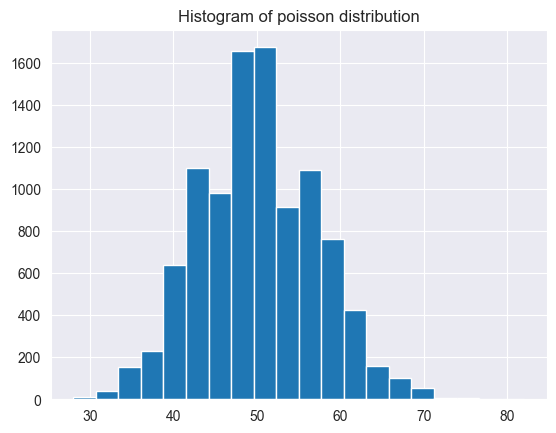

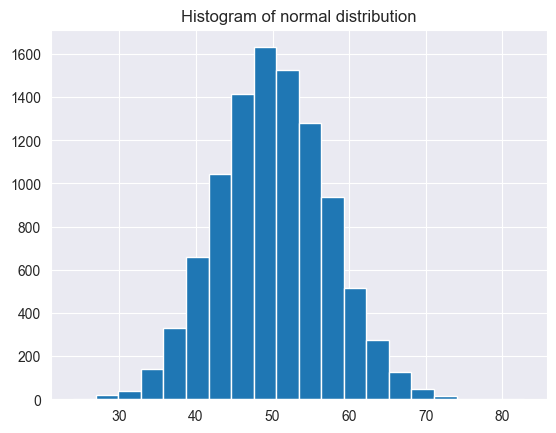

In [62]:
# Your code
amount=10000
poisson=rng.poisson(50,amount)
print("Poisson")
print((pd.Series(poisson).describe()),"\n")
poisson=rng.poisson(50,amount)
normal=rng.normal(poisson.mean(),poisson.std(),amount)
print("Normal")
print((pd.Series(normal).describe()))
plt.hist(poisson,bins=20)
plt.title("Histogram of poisson distribution")
plt.show()
plt.hist(normal,bins=20)
plt.title("Histogram of normal distribution")
plt.show()

**Question**

- By comparing the descriptive statistics and histograms, explain the similarities and differences between Poisson and normal distribution.

**Answer**

- The mean is almost the same. Poisson contains whole numbers, normal contains numbers that have decimals. Both have bell curve shape. Interqaurtile range is almost the same